# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")


def find_repo_root(start=Path.cwd()):
    """Find the homework folder by locating its pyproject.toml."""
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path

    raise RuntimeError(
        "Could not find the homework repository. "
        "Open this notebook from the homework folder."
    )


ROOT = find_repo_root()
DATA = ROOT / "data"

print("Homework folder:", ROOT)
print("Data folder:", DATA)

Homework folder: c:\Users\asadh\ceu\Coding-2-Python-for-Data-Analysis\coding2-debug-12-simple-linear-regression
Data folder: c:\Users\asadh\ceu\Coding-2-Python-for-Data-Analysis\coding2-debug-12-simple-linear-regression\data


In [11]:
df = pd.read_csv(DATA / "career_outcomes.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (240, 8)

Column names:
['experience_years', 'education_years', 'training_hours', 'sector', 'remote', 'ai_tool_use', 'salary_k_eur', 'promoted']

First five rows:


,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


In [12]:
print("Missing values:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

print("\nTraining hours range:")
print(df["training_hours"].min(), "to", df["training_hours"].max())

print("\nSalary range (thousand EUR):")
print(df["salary_k_eur"].min(), "to", df["salary_k_eur"].max())

Missing values:


experience_years    0
education_years     0
training_hours      0
sector              0
remote              0
ai_tool_use         0
salary_k_eur        0
promoted            0
dtype: int64


Summary statistics:


,experience_years,education_years,training_hours,remote,ai_tool_use,salary_k_eur,promoted
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,6.549167,15.591667,39.675417,0.350000,6.435833,75.679583,0.700000
std,3.702086,1.701566,16.086017,0.477966,2.215986,15.677923,0.459215
min,1.200000,12.000000,0.000000,0.000000,0.700000,36.200000,0.000000
25%,3.775000,14.000000,28.950000,0.000000,4.975000,64.725000,0.000000
50%,5.750000,16.000000,39.300000,0.000000,6.500000,74.450000,1.000000
75%,8.525000,16.000000,49.825000,1.000000,8.000000,86.525000,1.000000
max,18.600000,18.000000,90.000000,1.000000,10.000000,119.800000,1.000000



Training hours range:
0.0 to 90.0

Salary range (thousand EUR):
36.2 to 119.8


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

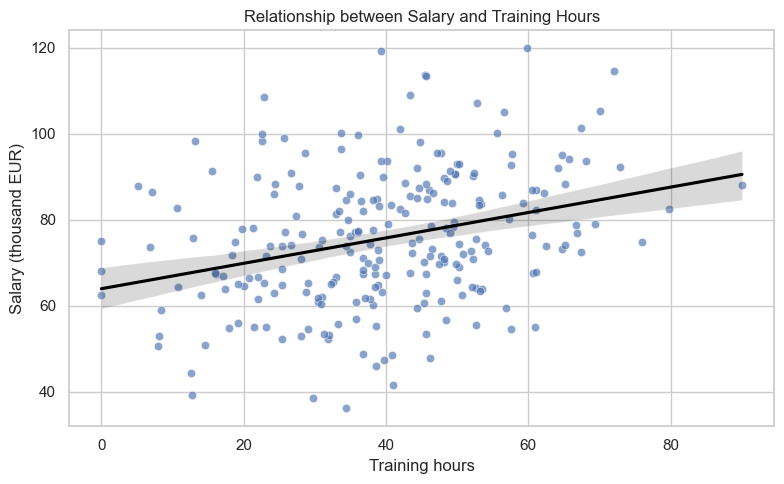

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="training_hours",
    y="salary_k_eur",
    alpha=0.65,
    ax=ax
)

sns.regplot(
    data=df,
    x="training_hours",
    y="salary_k_eur",
    scatter=False,
    color="black",
    ci=95,
    ax=ax
)

ax.set(
    title="Relationship between Salary and Training Hours",
    xlabel="Training hours",
    ylabel="Salary (thousand EUR)"
)

plt.tight_layout()
plt.show()

In [14]:
model = smf.ols(
    formula="salary_k_eur ~ training_hours",
    data=df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        22:32:01   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [15]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]

training_sd = df["training_hours"].std()

print(f"Intercept: {intercept:.2f} thousand EUR")
print(f"Slope: {slope:.4f} thousand EUR per training hour")
print(f"Training-hours standard deviation: {training_sd:.2f} hours")

print(
    f"Estimated salary difference for 10 additional training hours: "
    f"{10 * slope:.2f} thousand EUR"
)

Intercept: 63.97 thousand EUR
Slope: 0.2951 thousand EUR per training hour
Training-hours standard deviation: 16.09 hours
Estimated salary difference for 10 additional training hours: 2.95 thousand EUR


In [16]:
new_workers = pd.DataFrame({
    "training_hours": [10, 40, 80]
})

predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)

results = new_workers.copy()

results["predicted_salary"] = predictions["mean"]

results["mean_ci_lower"] = predictions["mean_ci_lower"]
results["mean_ci_upper"] = predictions["mean_ci_upper"]

results["individual_pi_lower"] = predictions["obs_ci_lower"]
results["individual_pi_upper"] = predictions["obs_ci_upper"]

display(results.round(2))

,training_hours,predicted_salary,mean_ci_lower,mean_ci_upper,individual_pi_lower,individual_pi_upper
0,10,66.92,62.92,70.92,37.15,96.69
1,40,75.78,73.87,77.68,46.22,105.33
2,80,87.58,82.43,92.73,57.64,117.52


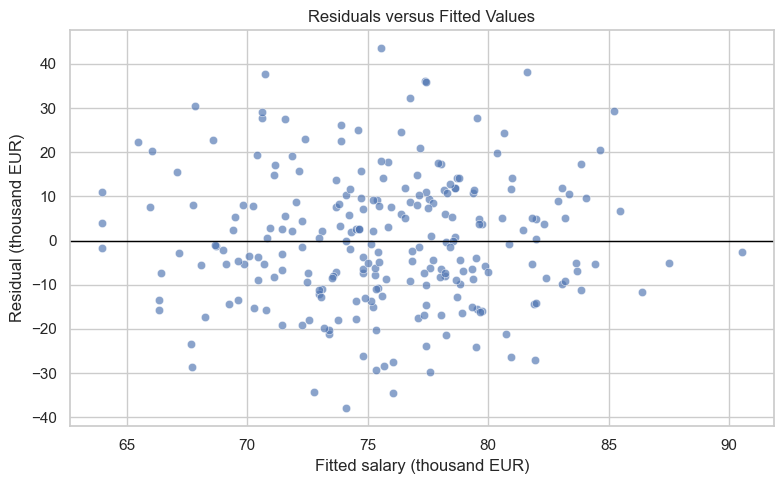

In [17]:
diagnostics = df.assign(
    fitted=model.fittedvalues,
    residual=model.resid
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=diagnostics,
    x="fitted",
    y="residual",
    alpha=0.65,
    ax=ax
)

ax.axhline(0, color="black", linewidth=1)

ax.set(
    title="Residuals versus Fitted Values",
    xlabel="Fitted salary (thousand EUR)",
    ylabel="Residual (thousand EUR)"
)

plt.tight_layout()
plt.show()

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

Residuals versus Fitted Values
The residuals are generally scattered around the horizontal zero line, with both positive and negative values across the range of fitted salaries (approximately €64,000–€91,000).

Key observations:

1. Residuals centred around zero: Most points are distributed on both sides of zero, suggesting that the model does not consistently overestimate or underestimate salaries.

2. No strong systematic pattern: There is no obvious curved or U-shaped pattern. This suggests that a linear relationship between training hours and salary may be a reasonable approximation.

3. Variation in residuals: The spread of residuals appears relatively broad across the fitted values. There is no very clear funnel-shaped pattern, although the plot alone cannot rule out heteroscedasticity.

4. Some large residuals: A few observations have residuals above +30 or below −30 thousand EUR. These may represent unusual observations that deserve further investigation.